# BÀI 2 (TRANG 15-16): PHÂN LỚP DỮ LIỆU ADULT INCOME
- **Sinh viên thực hiện:** Dương Đại Phát
- **MSSV:** 6451071058
- **Nguồn dataset:** Google Drive (`adult.data.csv`, `adult.test.csv`)

In [1]:
print("Dương Đại Phát - 6451071058")
import os
import subprocess
import sys

files_to_download = {
    "adult.data.csv": "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB",
    "adult.test.csv": "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD",
}
for fname, fid in files_to_download.items():
    if not os.path.exists(fname):
        subprocess.check_call([sys.executable, "-m", "gdown", f"https://drive.google.com/uc?id={fid}", "-O", fname])

Dương Đại Phát - 6451071058


## Câu 1: Import thư viện và nhập dữ liệu đầu vào

In [2]:
%matplotlib inline
print("Dương Đại Phát - 6451071058")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

train_raw = pd.read_csv('adult.data.csv', skipinitialspace=True)
test_raw = pd.read_csv('adult.test.csv', skipinitialspace=True)

print("Số lượng dữ liệu huấn luyện ban đầu (adult.data.csv):", len(train_raw))
print("Số lượng dữ liệu kiểm thử ban đầu (adult.test.csv):", len(test_raw))

Dương Đại Phát - 6451071058


Số lượng dữ liệu huấn luyện ban đầu (adult.data.csv): 32561
Số lượng dữ liệu kiểm thử ban đầu (adult.test.csv): 16281


## Câu 2: Tiền xử lý dữ liệu (xóa dòng trống `?`, xóa cột `fnlwgt`, nối dữ liệu)

In [3]:
print("Dương Đại Phát - 6451071058")
train_data = train_raw.replace('?', np.nan).dropna().copy()
test_data = test_raw.replace('?', np.nan).dropna().copy()

print("Number of training data:", len(train_data))
print("Number of test data:", len(test_data))

if 'fnlwgt' in train_data.columns:
    train_data = train_data.drop('fnlwgt', axis=1)

data = pd.concat([train_data, test_data], ignore_index=True)
data.info()

Dương Đại Phát - 6451071058
Number of training data: 30162
Number of test data: 15060
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             45222 non-null  int64 
 1   workclass       45222 non-null  object
 2   education       45222 non-null  object
 3   education-num   45222 non-null  int64 
 4   marital-status  45222 non-null  object
 5   occupation      45222 non-null  object
 6   relationship    45222 non-null  object
 7   race            45222 non-null  object
 8   sex             45222 non-null  object
 9   capital-gain    45222 non-null  int64 
 10  capital-loss    45222 non-null  int64 
 11  hours-per-week  45222 non-null  int64 
 12  native-country  45222 non-null  object
 13  income          45222 non-null  object
dtypes: int64(5), object(9)
memory usage: 4.8+ MB


## Câu 3: Khảo sát độ tương đồng giữa các cột bằng hệ số Pearson

Dương Đại Phát - 6451071058


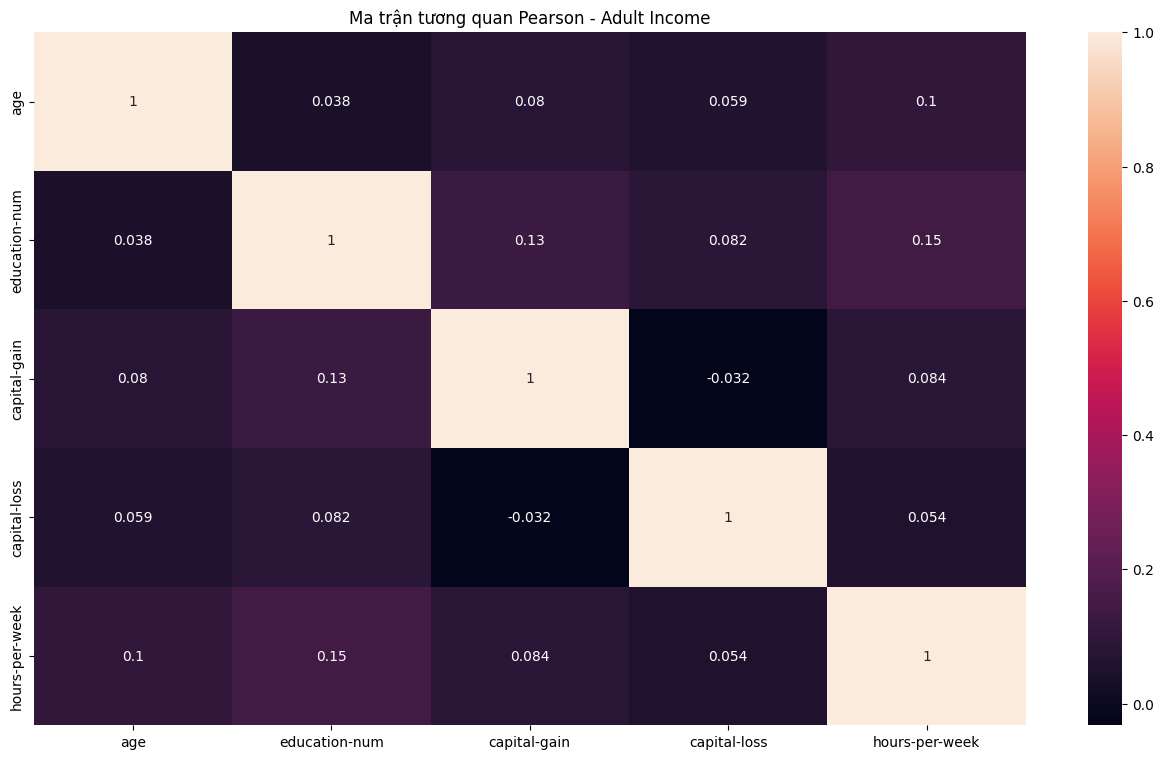

Nhận xét: Các giá trị tương quan ngoài đường chéo đều nhỏ (lớn nhất khoảng 0.15),
không có thuộc tính nào tương đồng cao nên không cần loại bỏ cột nào.


In [4]:
print("Dương Đại Phát - 6451071058")
plt.figure(figsize=(16, 9))
corr_matrix = data.corr(method='pearson', numeric_only=True)
sns.heatmap(corr_matrix, annot=True)
plt.title("Ma trận tương quan Pearson - Adult Income")
plt.show()

print("Nhận xét: Các giá trị tương quan ngoài đường chéo đều nhỏ (lớn nhất khoảng 0.15),")
print("không có thuộc tính nào tương đồng cao nên không cần loại bỏ cột nào.")

## Câu 4: Tách thuộc tính bình thường (`features`) và thuộc tính quyết định (`labels`)

In [5]:
print("Dương Đại Phát - 6451071058")
features = data.drop('income', axis=1)
labels = data['income']
print("Features shape:", features.shape)
print("Labels shape:", labels.shape)
print("Phân bố nhãn:\n", labels.value_counts())

Dương Đại Phát - 6451071058
Features shape: (45222, 13)
Labels shape: (45222,)
Phân bố nhãn:
 income
<=50K    34014
>50K     11208
Name: count, dtype: int64


## Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector

In [6]:
print("Dương Đại Phát - 6451071058")
non_numeric_cols = features.select_dtypes(exclude=['int64', 'float64']).columns
print("Các cột không phải dạng số:", non_numeric_cols)

features_onehot = pd.get_dummies(features, columns=non_numeric_cols, dtype=int)
print("Kích thước sau khi one-hot:", features_onehot.shape)
features_onehot.head()

Dương Đại Phát - 6451071058
Các cột không phải dạng số: Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')
Kích thước sau khi one-hot: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


## Câu 6: Tách dữ liệu thành tập huấn luyện và tập kiểm thử như ban đầu

In [7]:
print("Dương Đại Phát - 6451071058")
n_train = len(train_data)
X_train = features_onehot[:n_train]
X_test = features_onehot[n_train:]
y_train = labels[:n_train]
y_test = labels[n_train:]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)

Dương Đại Phát - 6451071058
X_train: (30162, 103) | y_train: (30162,)
X_test: (15060, 103) | y_test: (15060,)


## Câu 7: Xây dựng cây quyết định ID3 (`criterion='entropy'`) và đánh giá

Dương Đại Phát - 6451071058


ID3 Accuracy: 0.8175298804780876
Report:
               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



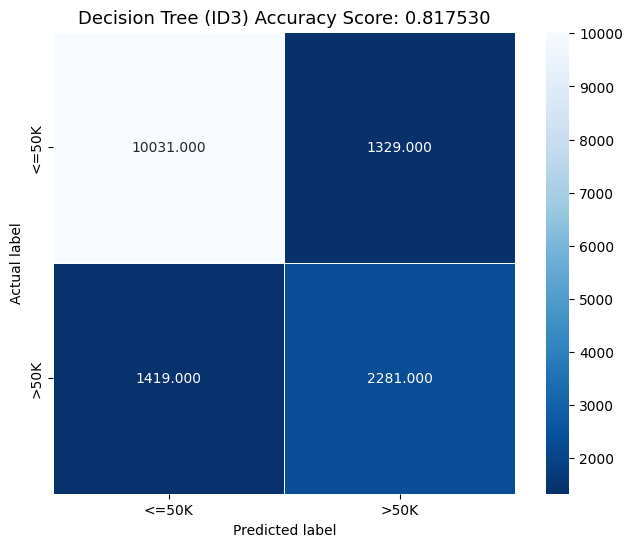

In [8]:
print("Dương Đại Phát - 6451071058")
clf_id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf_id3.fit(X_train, y_train)
id3_pred = clf_id3.predict(X_test)

id3_score = metrics.accuracy_score(y_test, id3_pred)
print("ID3 Accuracy:", id3_score)
print("Report:\n", metrics.classification_report(y_test, id3_pred))

id3_cm = metrics.confusion_matrix(y_test, id3_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(id3_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf_id3.classes_, yticklabels=clf_id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (ID3) Accuracy Score: {id3_score:.6f}', size=13)
plt.show()

Dương Đại Phát - 6451071058


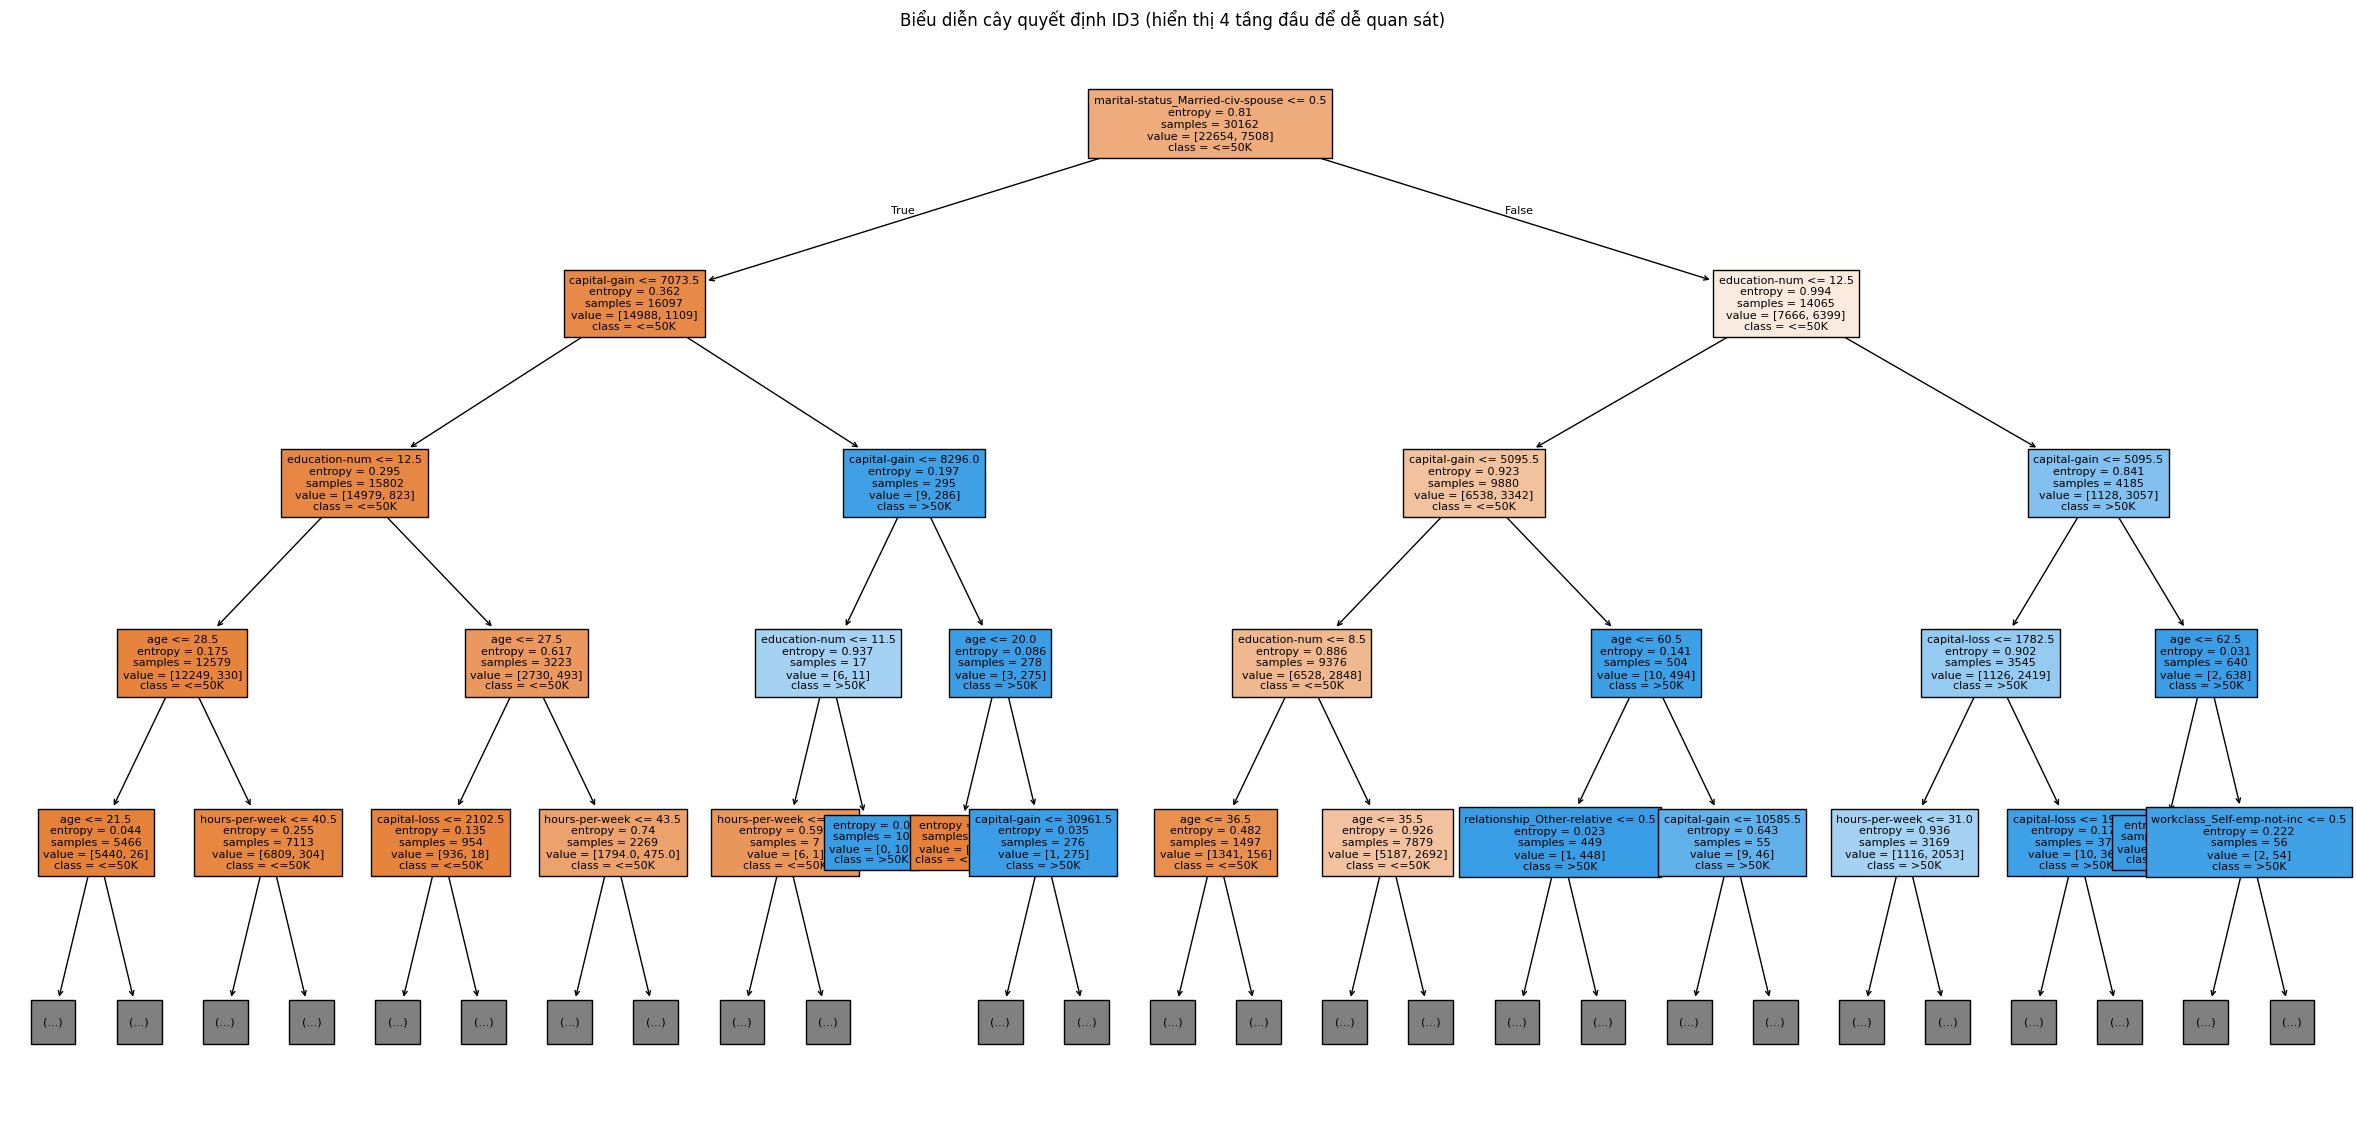

In [9]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(30, 14))
tree.plot_tree(clf_id3, filled=True, fontsize=8, max_depth=4, feature_names=features_onehot.columns, class_names=clf_id3.classes_)
plt.title("Biểu diễn cây quyết định ID3 (hiển thị 4 tầng đầu để dễ quan sát)")
plt.savefig('decision_tree_id3_preview.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 8: Xây dựng cây quyết định CART (`criterion='gini'`) và đánh giá

Dương Đại Phát - 6451071058


CART Accuracy: 0.8122841965471448
Report:
               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



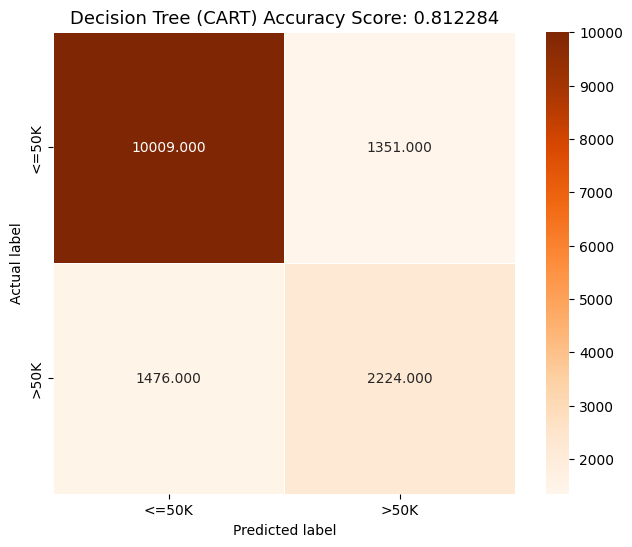

In [10]:
print("Dương Đại Phát - 6451071058")
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)
cart_pred = clf_cart.predict(X_test)

cart_score = metrics.accuracy_score(y_test, cart_pred)
print("CART Accuracy:", cart_score)
print("Report:\n", metrics.classification_report(y_test, cart_pred))

cart_cm = metrics.confusion_matrix(y_test, cart_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cart_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Oranges',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree (CART) Accuracy Score: {cart_score:.6f}', size=13)
plt.show()

Dương Đại Phát - 6451071058


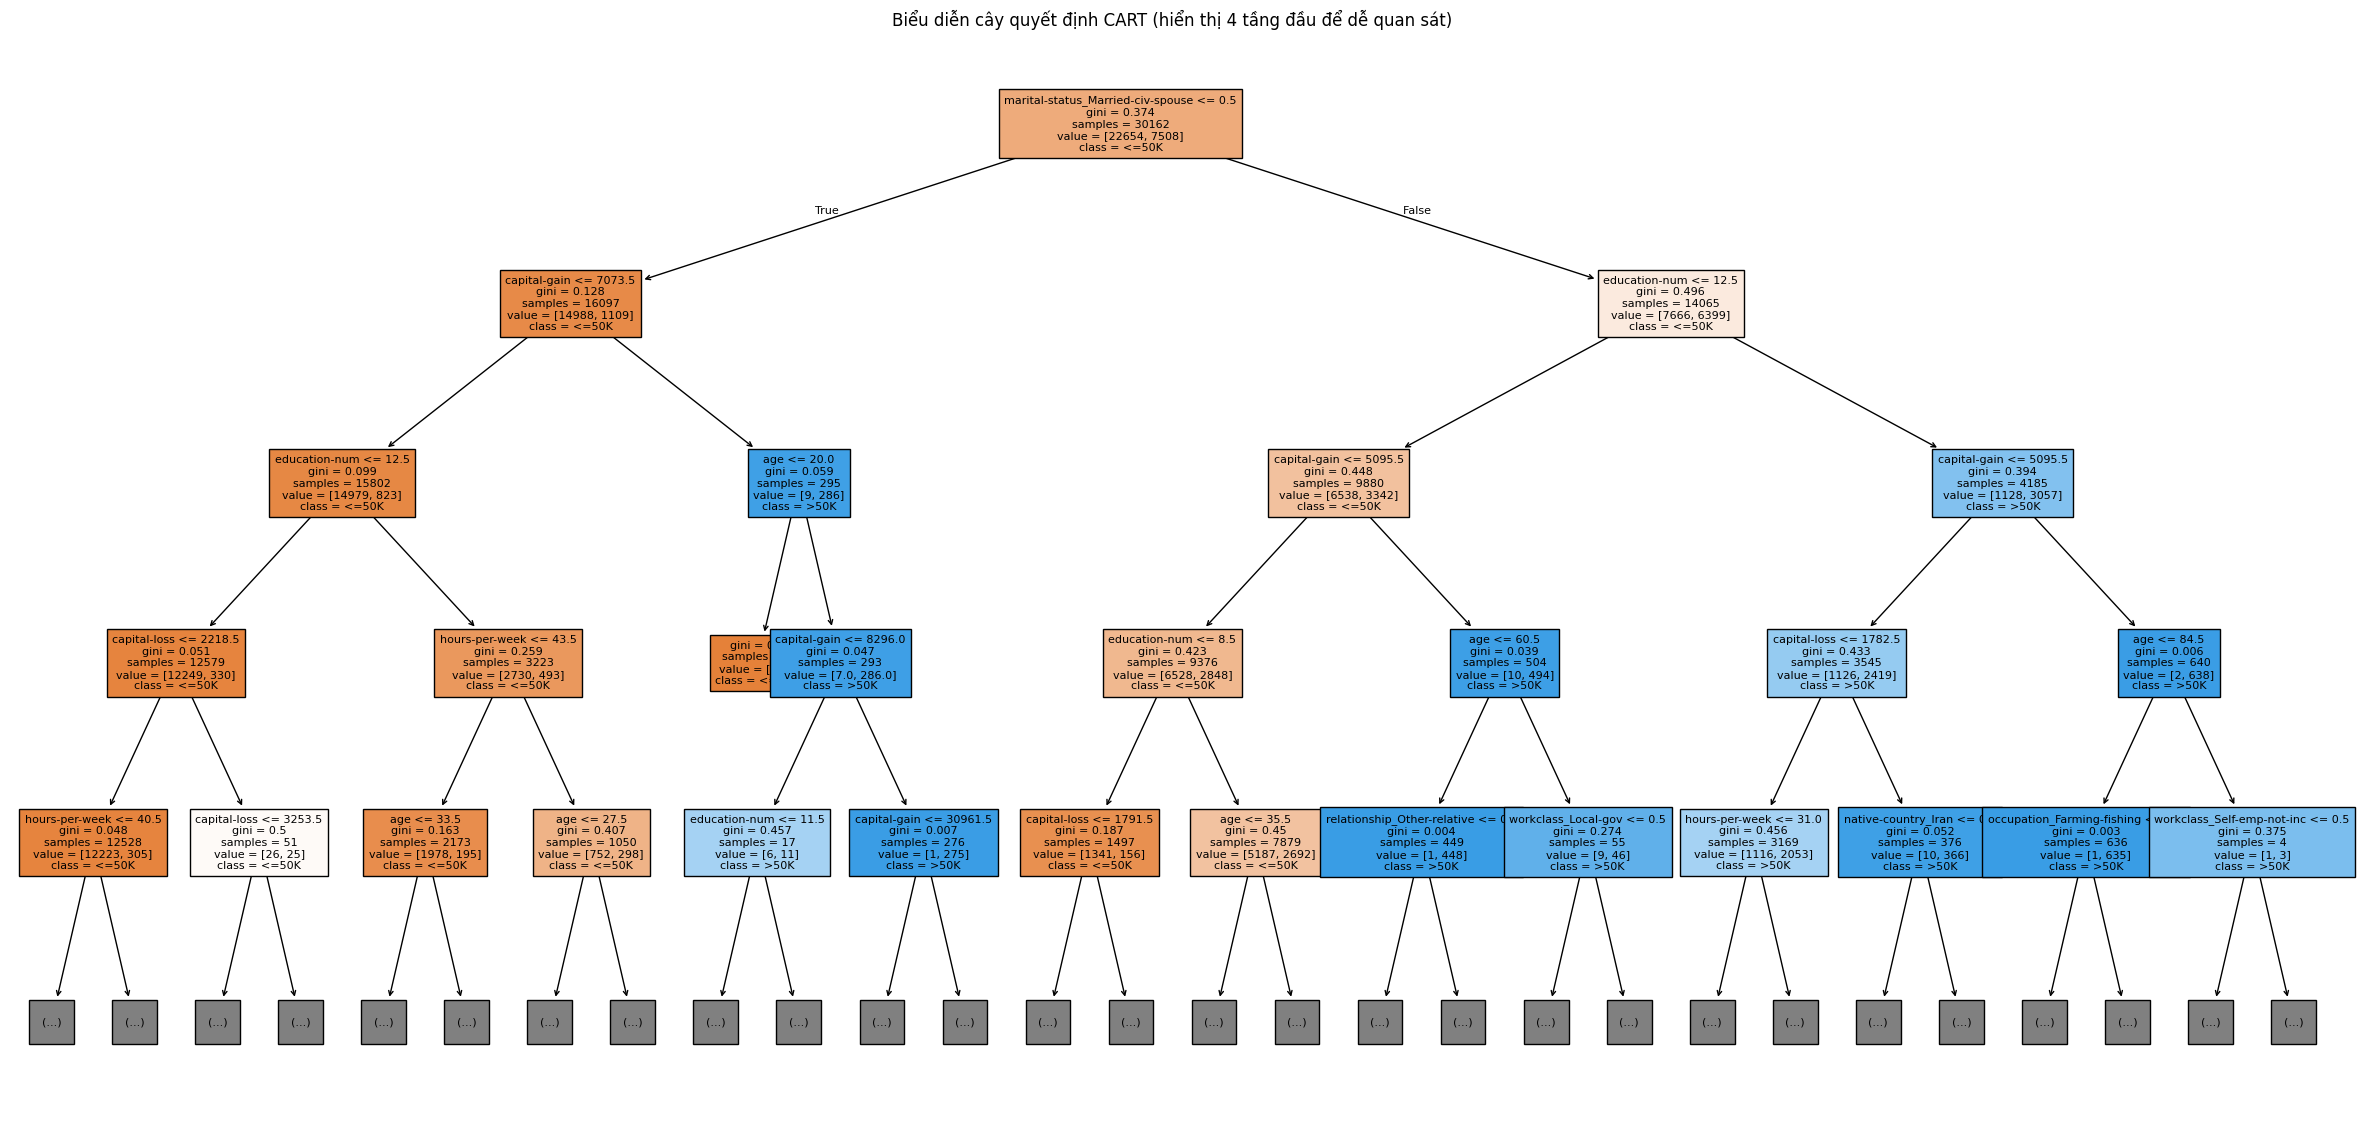

In [11]:
print("Dương Đại Phát - 6451071058")
fig, ax = plt.subplots(figsize=(30, 14))
tree.plot_tree(clf_cart, filled=True, fontsize=8, max_depth=4, feature_names=features_onehot.columns, class_names=clf_cart.classes_)
plt.title("Biểu diễn cây quyết định CART (hiển thị 4 tầng đầu để dễ quan sát)")
plt.savefig('decision_tree_cart_preview.png', dpi=100, bbox_inches='tight')
plt.show()

## Câu 9: Xây dựng mô hình Naïve Bayes (`GaussianNB`) và đánh giá

Dương Đại Phát - 6451071058
Naive Bayes Accuracy: 0.8029216467463479


Report:
               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



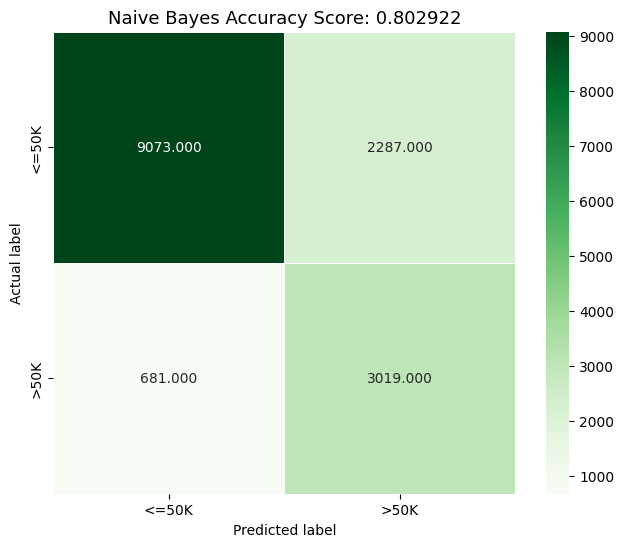

In [12]:
print("Dương Đại Phát - 6451071058")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Naive Bayes Accuracy:", bayes_score)
print("Report:\n", metrics.classification_report(y_test, bayes_pred))

bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score:.6f}', size=13)
plt.show()

## Câu 10: So sánh kết quả của các mô hình

In [13]:
print("Dương Đại Phát - 6451071058")
results = []
for name, pred in [("ID3 (Entropy)", id3_pred), ("CART (Gini)", cart_pred), ("Naive Bayes", bayes_pred)]:
    results.append({
        "Mô hình": name,
        "Accuracy": round(metrics.accuracy_score(y_test, pred), 4),
        "Precision (Macro)": round(metrics.precision_score(y_test, pred, average='macro'), 4),
        "Recall (Macro)": round(metrics.recall_score(y_test, pred, average='macro'), 4),
        "F1-score (Macro)": round(metrics.f1_score(y_test, pred, average='macro'), 4),
        "F1-score (Weighted)": round(metrics.f1_score(y_test, pred, average='weighted'), 4),
    })

df_compare = pd.DataFrame(results)
print(df_compare.to_string(index=False))

print("\nNhận xét:")
print("- Cây quyết định ID3 đạt Accuracy cao nhất (~81.75%), nhỉnh hơn một chút so với CART (~81.23%) và cao hơn Naive Bayes (~80.29%).")
print("- Tuy nhiên, Naive Bayes có Recall cho lớp >50K cao hơn (0.82 so với 0.62 của ID3), dẫn tới Macro Recall cao hơn nhưng Precision của lớp >50K thấp hơn (nhiều FP hơn).")
print("- Cây quyết định (ID3/CART) đạt độ cân bằng tốt hơn giữa Precision và Recall trên tập Adult Income khi dùng dữ liệu đã one-hot encoding.")

Dương Đại Phát - 6451071058


      Mô hình  Accuracy  Precision (Macro)  Recall (Macro)  F1-score (Macro)  F1-score (Weighted)
ID3 (Entropy)    0.8175             0.7540          0.7497            0.7518               0.8168
  CART (Gini)    0.8123             0.7468          0.7411            0.7438               0.8112
  Naive Bayes    0.8029             0.7496          0.8073            0.7649               0.8130

Nhận xét:
- Cây quyết định ID3 đạt Accuracy cao nhất (~81.75%), nhỉnh hơn một chút so với CART (~81.23%) và cao hơn Naive Bayes (~80.29%).
- Tuy nhiên, Naive Bayes có Recall cho lớp >50K cao hơn (0.82 so với 0.62 của ID3), dẫn tới Macro Recall cao hơn nhưng Precision của lớp >50K thấp hơn (nhiều FP hơn).
- Cây quyết định (ID3/CART) đạt độ cân bằng tốt hơn giữa Precision và Recall trên tập Adult Income khi dùng dữ liệu đã one-hot encoding.
